# 01. 불량 시나리오 데이터 생성
정상 셀(교반 2회로 개선한 샘플2)의 충방전 데이터에 **불량 6종을 주입**해, 탐지·보정 알고리즘을 만들고 검증할 **불량 시나리오 데이터**를 만듭니다.
실제 용량 저하 셀의 충방전 원본과는 별개의 데이터입니다.

| 불량 유형 | 주입 방식 |
|---|---|
| 센서 스파이크 | 전압이 한 점만 ±0.15~0.30 V 튐 |
| 내부 단락 의심 | 방전 중 전압이 정상보다 최대 0.12 V 더 떨어졌다가 회복 |
| 센서 고착 | 전압이 한 값에서 200개 샘플 동안 변하지 않음 |
| 데이터 누락 | 전압이 40개 샘플 동안 비어 있음 |
| 과전압 | 충전 끝에서 4.2 V를 넘어 4.35 V까지 상승 |
| 용량 글리치 | 누적 용량이 한 점만 +0.00008 튐 |

시드를 고정(42)해서 실행할 때마다 같은 결과가 나옵니다. 결과는 `data/불량 시나리오 데이터.xlsx`로 저장됩니다.

불량 유형별 개수
불량유형
정상          33464
내부 단락 의심     1000
센서 고착         200
과전압           151
데이터 누락         40
센서 스파이크         6
용량 글리치          3

전체 34864행 중 불량 1400행 (4.0%)


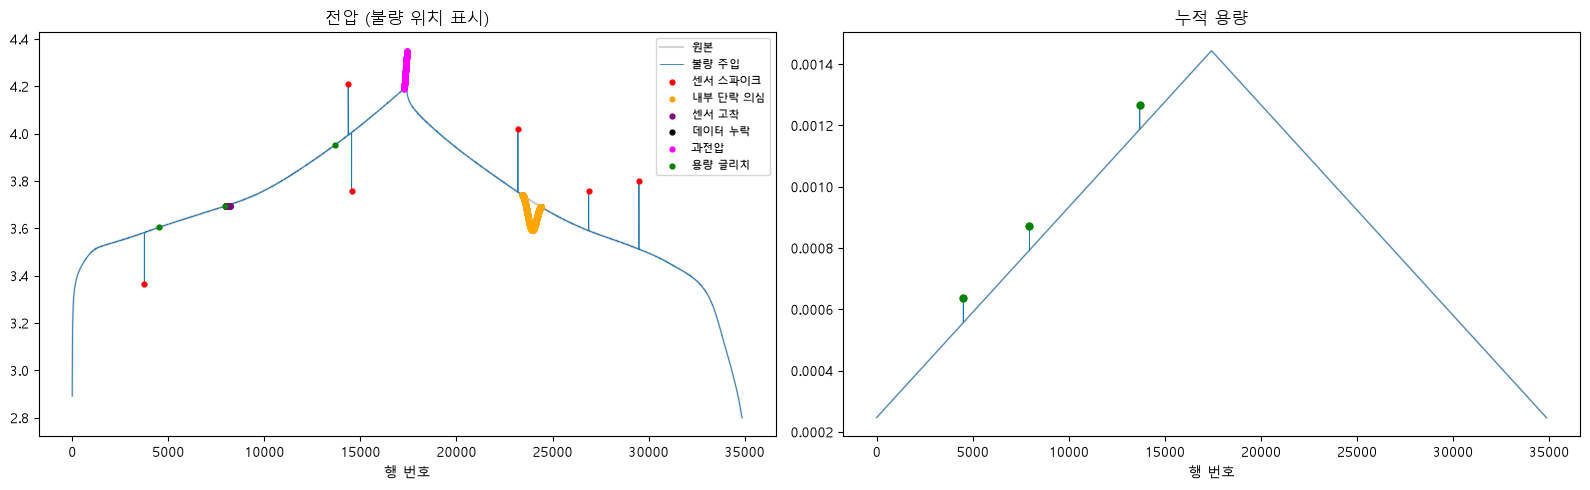

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

from pathlib import Path

# 저장소 루트에서 실행하든 notebooks/ 폴더에서 실행하든 동작
DATA_DIR = next(p for p in (Path("data"), Path("../data")) if p.exists())
OUT_DIR = DATA_DIR.parent / "outputs"          # 생성되는 결과 파일 (git에는 올리지 않음)
IMG_DIR = DATA_DIR.parent / "images"
OUT_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)

# ===== 불량 시나리오 데이터 생성 (원본은 그대로 두고 복사본에 불량을 주입) =====
rng = np.random.default_rng(42)   # 시드 고정 -> 매번 같은 불량이 만들어짐

df = pd.read_excel(DATA_DIR / "전압 및 용량 데이터.xlsx")
V = df['전압(V)'].to_numpy(dtype=float).copy()
Q = df['누적 용량_d(Ah/cm2)'].to_numpy(dtype=float).copy()
n = len(df)
imax = int(np.argmax(V))          # 충전 -> 방전 전환 지점 (17427행)

label = np.full(n, '정상', dtype=object)

# 1) 센서 스파이크: 전압이 한 점만 순간적으로 튐 (노이즈/접촉 불량)
pool = np.r_[1000:imax-1000, imax+1000:n-1000]
for i in rng.choice(pool, 6, replace=False):
    V[i] += rng.choice([-1, 1]) * rng.uniform(0.15, 0.30)
    label[i] = '센서 스파이크'

# 2) 내부 단락(미세 단락): 방전 중 전압이 정상보다 점점 더 떨어졌다가 회복
s, L = imax + 6000, 1000
V[s:s+L] -= 0.12 * np.sin(np.linspace(0, np.pi, L)) ** 2
label[s:s+L] = '내부 단락 의심'

# 3) 센서 고착(flatline): 전압 값이 일정 구간 동안 변하지 않음
s, L = 8000, 200
V[s:s+L] = V[s]
label[s:s+L] = '센서 고착'

# 4) 데이터 누락: 일정 구간 전압이 측정되지 않음
s, L = 12000, 40
V[s:s+L] = np.nan
label[s:s+L] = '데이터 누락'

# 5) 과전압: 충전 끝에서 전압이 상한(4.2V)을 넘어 계속 상승
V[imax-150:imax+1] += np.linspace(0, 0.15, 151)
label[imax-150:imax+1] = '과전압'

# 6) 용량 글리치: 누적 용량이 한 점만 갑자기 튐 (카운터 오류)
for i in rng.choice(np.r_[1000:imax-1000], 3, replace=False):
    Q[i] += 0.00008
    label[i] = '용량 글리치'

df_bad = df.copy()
df_bad['전압(V)'] = V
df_bad['누적 용량_d(Ah/cm2)'] = Q
df_bad['불량'] = (label != '정상').astype(int)
df_bad['불량유형'] = label

df_bad.to_excel(DATA_DIR / "불량 시나리오 데이터.xlsx", index=False)

print("불량 유형별 개수")
print(df_bad['불량유형'].value_counts().to_string())
print(f"\n전체 {n}행 중 불량 {df_bad['불량'].sum()}행 ({df_bad['불량'].mean()*100:.1f}%)")

# ===== 시각화 =====
colors = {'센서 스파이크': 'red', '내부 단락 의심': 'orange', '센서 고착': 'purple',
          '데이터 누락': 'black', '과전압': 'magenta', '용량 글리치': 'green'}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(df_bad.index, df['전압(V)'], color='lightgray', label='원본')
axes[0].plot(df_bad.index, df_bad['전압(V)'], color='tab:blue', lw=0.6, label='불량 주입')
axes[1].plot(df_bad.index, df['누적 용량_d(Ah/cm2)'], color='lightgray')
axes[1].plot(df_bad.index, df_bad['누적 용량_d(Ah/cm2)'], color='tab:blue', lw=0.6)
for name, c in colors.items():
    m = (df_bad['불량유형'] == name).to_numpy()
    axes[0].scatter(df_bad.index[m], df_bad['전압(V)'][m], s=12, color=c, label=name, zorder=3)
    if name == '용량 글리치':
        axes[1].scatter(df_bad.index[m], df_bad['누적 용량_d(Ah/cm2)'][m], s=25, color=c, zorder=3)
axes[0].set_title('전압 (불량 위치 표시)'); axes[0].set_xlabel('행 번호'); axes[0].legend(fontsize=8)
axes[1].set_title('누적 용량'); axes[1].set_xlabel('행 번호')
plt.tight_layout()
plt.show()